# M03-3 | 從零寫一個規則式 Quantizer：只量化 conv2d

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m03_quantizer_api/03_my_first_quantizer.ipynb)

M03-1 的 `LabelQuantizer` 是**點名**：我們告訴它「在 relu 的輸出貼標籤」。換一個模型，node 的名字就不一樣了，點名沒辦法推廣。
真實的 Quantizer 靠**規則**找 node：

$$
\text{Quantizer} = \text{找 node 的規則} + \text{每個位置用哪一份 spec}
$$

這本 notebook 寫一個 `ConvOnlyQuantizer`：

- 規則：`node.target` 是 `aten.conv2d` 的 node。
- 規格：activation 用 int8 per-tensor affine、weight 用 int8 per-channel symmetric（`common/qspecs.py` 的 `act_spec()`、`weight_spec()`）。

段落：

- **A.** 寫出來：`annotate` 的三個動作。
- **B.** 和 XNNPACKQuantizer 比：conv 和 relu 之間的 observer。
- **C.** `validate`：不支援的圖在 prepare 就報錯。
- **D.** 這個 Quantizer 還缺什麼。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m03_quantizer_api")

In [1]:
import copy

import torch

from common.data import calibration_batches
from common.graph_utils import observer_nodes, qdq_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import annotation_notes, draw, table

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default

## A. 寫出來：annotate 的三個動作

`annotate` 對每個 node 做三件事：

1. **找 node**：用 `node.target` 比對 op，不看名字。
2. **貼標籤**：torchao 提供兩個公開的輔助函式，`annotate_input_qspec_map(node, 上游, spec)` 標一條輸入邊、`annotate_output_qspec(node, spec)` 標輸出。它們會在需要時建立 `QuantizationAnnotation`，不必自己 new。
3. **標記已處理**：設 `_annotated = True`。開頭也要檢查它，已經被標過的 node 就跳過。多個 Quantizer 組合時，這是「不搶別人的 node」的約定（M03-6）。

In [2]:
class ConvOnlyQuantizer(Quantizer):
    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op != "call_function" or node.target != CONV2D:  # (1) 找 node
                continue
            ann = node.meta.get(ANNOTATION_KEY)
            if ann is not None and ann._annotated:  # (3) 已經被標過就不動
                continue
            activation, weight = node.args[0], node.args[1]
            annotate_input_qspec_map(node, activation, act_spec())  # (2) 貼標籤
            annotate_input_qspec_map(node, weight, weight_spec())
            annotate_output_qspec(node, act_spec())
            node.meta[ANNOTATION_KEY]._annotated = True  # (3)
        return model

    def validate(self, model):
        """weight 必須是模型常數（get_attr），否則無法預先量化。"""
        for node in model.graph.nodes:
            if node.op == "call_function" and node.target == CONV2D and node.args[1].op != "get_attr":
                raise ValueError(f"{node.name} 的 weight 來自 {node.args[1].op} node「{node.args[1].name}」，"
                                 "ConvOnlyQuantizer 只支援常數 weight")

bias（`node.args[2]`）沒有放進 `input_qspec_map`，所以不量化。直接呼叫 `annotate` 看標籤：

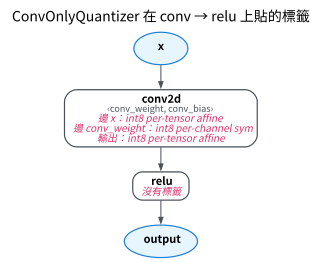

In [3]:
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
q = ConvOnlyQuantizer()
q.annotate(gm)
draw(gm, notes=annotation_notes(gm, unlabeled=True), title="ConvOnlyQuantizer 在 conv → relu 上貼的標籤")

和 M03-2 A 段的 XNNPACKQuantizer 比，差在兩處：bias 這條邊根本不在標籤裡（XNNPACK 是列出來、規格寫 `None`，結果一樣不量化）；
而 **conv2d 自己有輸出標籤、relu 沒有標籤**。

再呼叫一次 `annotate`，標籤物件不會被換掉，因為開頭的 `_annotated` 檢查擋住了：

In [4]:
before = {n.name: id(n.meta[ANNOTATION_KEY]) for n in gm.graph.nodes if ANNOTATION_KEY in n.meta}
q.annotate(gm)
after = {n.name: id(n.meta[ANNOTATION_KEY]) for n in gm.graph.nodes if ANNOTATION_KEY in n.meta}
print("再呼叫一次 annotate，標籤物件相同？", before == after)
assert before == after

再呼叫一次 annotate，標籤物件相同？ True


## B. 和 XNNPACKQuantizer 比：conv 和 relu 之間的 observer

同一個 `conv_bn_relu` 模型，分別交給兩個 Quantizer 做 `prepare_pt2e`（BN 會先折進 conv），只畫 conv 與 relu 附近：

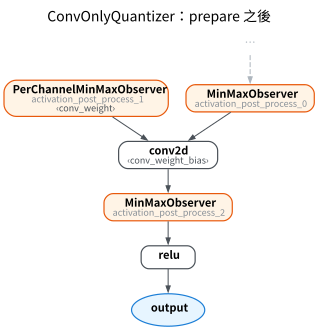

In [5]:
gm = export_module(get_model("conv_bn_relu").eval(), example_inputs(8))
mine = prepare_pt2e(copy.deepcopy(gm), ConvOnlyQuantizer())
draw(mine, focus=["conv2d", "relu"], title="ConvOnlyQuantizer：prepare 之後")

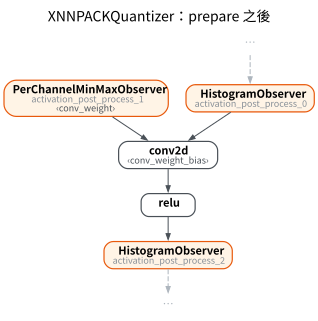

In [6]:
xnnpack, _ = get_xnnpack_quantizer(is_per_channel=True)
theirs = prepare_pt2e(copy.deepcopy(gm), xnnpack)
draw(theirs, focus=["conv2d", "relu"], title="XNNPACKQuantizer：prepare 之後")

In [7]:
def observer_before_relu(gm):
    """relu 的輸入是不是 observer：是的話，conv 與 relu 之間有量化點。"""
    relu = next(n for n in gm.graph.nodes if n.target == torch.ops.aten.relu.default)
    return relu.args[0].op == "call_module"


print("ConvOnlyQuantizer：conv 與 relu 之間有 observer？", observer_before_relu(mine))
print("XNNPACKQuantizer： conv 與 relu 之間有 observer？", observer_before_relu(theirs))
assert observer_before_relu(mine) and not observer_before_relu(theirs)

ConvOnlyQuantizer：conv 與 relu 之間有 observer？ True
XNNPACKQuantizer： conv 與 relu 之間有 observer？ False


`ConvOnlyQuantizer` 只認得 conv，不知道後面接了 relu，所以照規則在 conv 的輸出貼標籤，conv 與 relu 之間多了一個量化點。
XNNPACKQuantizer 認得 conv + relu 這個 pattern，輸出標籤貼在 relu，後端就能把兩個 op 當成一個 kernel 執行。
兩種圖都能跑，差別在後端能不能融合。

換成較大的 `tiny` 模型（conv、maxpool、add、pool、linear…），兩個 Quantizer 各自量化了多少：

In [8]:
def count(model_name, quantizer):
    prepared = prepare_pt2e(export_module(get_model(model_name).eval(), example_inputs(8)), quantizer)
    n_obs = len(observer_nodes(prepared))
    with torch.no_grad():
        for batch in calibration_batches(n=64, batch_size=16):
            prepared(*batch)
    return n_obs, len(qdq_nodes(convert_pt2e(prepared)))


rows = []
for name, quantizer in [("ConvOnlyQuantizer", ConvOnlyQuantizer()),
                        ("XNNPACKQuantizer", get_xnnpack_quantizer(is_per_channel=True)[0])]:
    rows.append([name, *count("tiny", quantizer)])
table(rows, ["Quantizer", "observer 數", "q/dq 數"])

Quantizer,observer 數,q/dq 數
ConvOnlyQuantizer,12,20
XNNPACKQuantizer,16,28


In [9]:
assert rows[0][1] < rows[1][1] and rows[0][2] < rows[1][2]

`ConvOnlyQuantizer` 只替 conv 貼標籤，maxpool、add、pool、linear 都沒有標籤、留在 fp32，所以 observer 與 q/dq 都比較少。
XNNPACKQuantizer 替更多種 op 貼了標籤。

## C. validate：不支援的圖在 prepare 就報錯

`annotate` 只管貼標籤；「這張圖我能不能處理」交給 `validate`。`prepare_pt2e` 在 `annotate` 之後、插 observer 之前呼叫它（M03-1），
所以使用者在校準之前就會知道。

下面的模型把 weight 當成輸入傳進來，而不是模型的參數。weight 不是常數，就無法預先量化成 int8：

In [10]:
class DynamicWeightConv(torch.nn.Module):
    def forward(self, x, w):
        return torch.nn.functional.conv2d(x, w, padding=1)


bad = export_module(DynamicWeightConv(), (torch.randn(1, 3, 8, 8), torch.randn(4, 3, 3, 3)), dynamic_batch=False)
try:
    prepare_pt2e(copy.deepcopy(bad), ConvOnlyQuantizer())
    raised = None
except ValueError as e:
    raised = e
print("ValueError:", raised)
assert raised is not None

ValueError: conv2d 的 weight 來自 placeholder node「w」，ConvOnlyQuantizer 只支援常數 weight


後端有硬體限制時，`validate` 就是檢查限制的地方（M10-1 用它擋下動態 batch）。

## D. 這個 Quantizer 還缺什麼

| 缺的東西 | 後果 | 在哪裡處理 |
|---|---|---|
| pattern | 不知道 conv 後面接 relu 可以融，量化點變多 | M03-6 標註順序、M04 fusion |
| 共用 qparams | add、cat 的輸入與輸出 scale 各自不同，整數運算前要先 rescale | M03-4 |
| bias 量化 | 後端常要求 int32 bias，scale 由 activation × weight 推導 | M03-5 |
| 設定介面 | 使用者無法指定「哪一部分用什麼規格、哪一部分不量化」 | M03-6、M03-7 |

## 小結

- 規則式 Quantizer 用 `node.target` 找 op，模型換了照樣適用。
- `annotate` 的三個動作：找 node、貼標籤（`annotate_input_qspec_map`、`annotate_output_qspec`）、標記 `_annotated`。
- 只認單一 op 的規則，會在 pattern 中間留下量化點；`validate` 讓不支援的圖在 prepare 時就報錯。